# Microscopic 3-Temperature-Model

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/dschick/udkm1Dsim/blob/develop/examples/02-heat/02-m3tm.ipynb)

Here we adapt the NTM from the [excitation & NTM example](#example_excitation_NTM) to allow for calculations of the magnetization within the microscopic 3-temperature-model.

:::{admonition} Reference {cite}`koopmans2010`
:class: seealso
B. Koopmans, G. Malinowski, F. Dalla Longa, et al.  
*Explaining the paradoxical diversity of ultrafast laser-induced demagnetization.*  
[Nature Mater 9, 259–265 (2010).](https://doi.org/10.1038/nmat2593)
:::

We need to solve the following coupled differential equations:

\begin{align*}
c_e(T_e) \rho \frac{\partial T_e}{\partial t} & = & \frac{\partial}{\partial z}
\left( k_e(T_e) \frac{\partial T_e}{\partial z} \right)
- G_{ep}(T_e-T_p) + S(z, t) \\
c_p(T_p) \rho \frac{\partial T_p}{\partial t} & = & \frac{\partial}{\partial z}
\left( k_p(T_p) \frac{\partial T_p}{\partial z} \right)
+ G_{ep}(T_e-T_p) \\
\frac{\partial m}{\partial t} & = & R m \frac{T_p}{T_C}
\left( 1 - m \coth\left( \frac{m T_C}{T_e} \right) \right)
\end{align*}

We treat the temperature of the 3rd subsystem as magnetization $m$.
For that we have to set its `heat_capacity` to $1/\rho$ and `thermal_conductivity` to zero.
We put the complete right term of the last equation in the `sub_system_coupling` term for the 3rd subsystem.
Here, we need to rewrite the kotangens hyperbolicus in Python as

$$\coth(x) = 1 + \frac{2}{e^{2x} - 1}$$

The values of the used parameters are not experimentally verified.

## Setup

Do all necessary imports and settings.

In [12]:
import matplotlib.pyplot as plt
import numpy as np

try:
    import udkm1Dsim as ud
except ImportError:
    %pip install udkm1Dsim
    import udkm1Dsim as ud

u = ud.u  # import the pint unit registry from udkm1Dsim
u.setup_matplotlib()  # use matplotlib with pint units

%matplotlib inline

## Structure

Refer to the [structure example](#example_structure) for more details.

In [13]:
Co = ud.Atom("Co")
Ni = ud.Atom("Ni")
CoNi = ud.AtomMixed("CoNi")
CoNi.add_atom(Co, 0.5)
CoNi.add_atom(Ni, 0.5)
Si = ud.Atom("Si")

In [14]:
prop_CoNi = {}
prop_CoNi["heat_capacity"] = ["0.1*T",
                              532 * u.J / u.kg / u.K,
                              1 / 7000]
prop_CoNi["therm_cond"] = [20 * u.W / (u.m * u.K),
                           80 * u.W / (u.m * u.K),
                           0]

R = 25.3 / 1e-12
Tc = 1388
g = 4.0e18

prop_CoNi["sub_system_coupling"] = [
    f"-{g:f}*(T_0-T_1)",
    f"{g:f}*(T_0-T_1)",
    f"{R:f}*T_2*T_1/{Tc:f}*(1-T_2* (1 + 2/(exp(2*T_2*{Tc:f}/T_0) - 1) ))",
]
prop_CoNi["lin_therm_exp"] = [0, 11.8e-6, 0]
prop_CoNi["deb_wal_fac"] = [0, 0, 0]
prop_CoNi["sound_vel"] = 4.910 * u.nm / u.ps
prop_CoNi["opt_ref_index"] = 2.9174 + 3.3545j

layer_CoNi = ud.Layer(
    "CoNi",
    "CoNi amorphous",
    thickness=1 * u.nm,
    density=7000 * u.kg / u.m**3,
    atom=CoNi,
    **prop_CoNi,
)

In [15]:
prop_Si = {}
prop_Si["heat_capacity"] = [100 * u.J / u.kg / u.K,
                            603 * u.J / u.kg / u.K,
                            1]
prop_Si["therm_cond"] = [0,
                         100 * u.W / (u.m * u.K),
                         0]

prop_Si["sub_system_coupling"] = [0, 0, 0]

prop_Si["lin_therm_exp"] = [0, 2.6e-6, 0]
prop_Si["deb_wal_fac"] = [0, 0, 0]
prop_Si["sound_vel"] = 8.433 * u.nm / u.ps
prop_Si["opt_ref_index"] = 3.6941 + 0.0065435j

layer_Si = ud.Layer(
    "Si", "Si amorphous", thickness=1 * u.nm, density=2336 * u.kg / u.m**3, atom=Si, **prop_Si
)

In [16]:
S = ud.Structure("CoNi")

S.add_sub_structure(layer_CoNi, 20)
S.add_sub_structure(layer_Si, 50)

# add semi-infinite, static substrate
S.add_substrate(layer_Si)

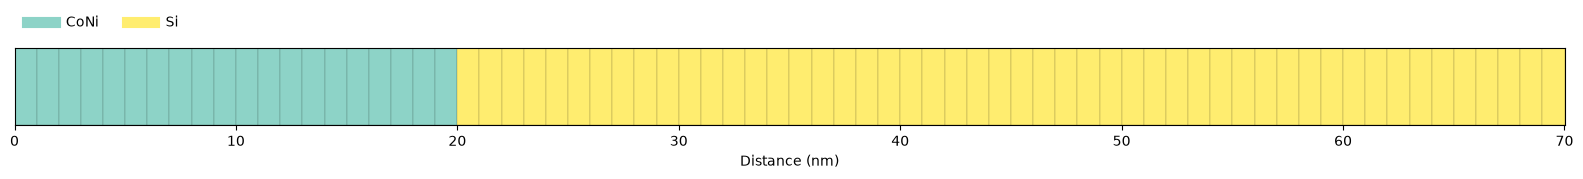

In [17]:
S.visualize()

## Initialize Heat and the Excitation

In [18]:
h = ud.Heat(S, True)

h.save_data = False
h.disp_messages = True

In [19]:
h.excitation = {
    "fluence": [30] * u.mJ / u.cm**2,
    "delay_pump": [0] * u.ps,
    "pulse_width": [0.05] * u.ps,
    "multilayer_absorption": True,
    "wavelength": 800 * u.nm,
    "theta": 45 * u.deg,
}
# temporal and spatial grid
delays = np.r_[-1:5:0.005] * u.ps
_, _, distances = S.get_distances_of_layers()

## Calculate Heat Diffusion

The `init_temp` sets the magnetization in the 3rd subsystem to `1` for CoNi and `0` for Si.

In [20]:
# enable heat diffusion
h.heat_diffusion = True
# set the boundary conditions
h.boundary_conditions = {"top_type": "isolator", "bottom_type": "isolator"}
# The resulting temperature profile is calculated in one line:

init_temp = np.ones([S.get_number_of_layers(), 3])
init_temp[:, 0] = 300
init_temp[:, 1] = 300
init_temp[20:, 2] = 0

temp_map, delta_temp = h.get_temp_map(delays, init_temp)

Surface incidence fluence scaled by factor 0.7071 due to incidence angle theta=45.00 deg
Calculating _heat_diffusion_ without excitation...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_: 0.446272 s
Calculating _heat_diffusion_ for excitation 1:1 ...
Absorption profile is calculated by multilayer formalism with p-polarization.
Total reflectivity of 42.4 % and transmission of 28.3 %.


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_ with 1 excitation(s): 0.334667 s
Calculating _heat_diffusion_ without excitation...


0it [00:00, ?it/s]

Elapsed time for _heat_diffusion_: 1.870353 s
Elapsed time for _temp_map_: 2.697575 s


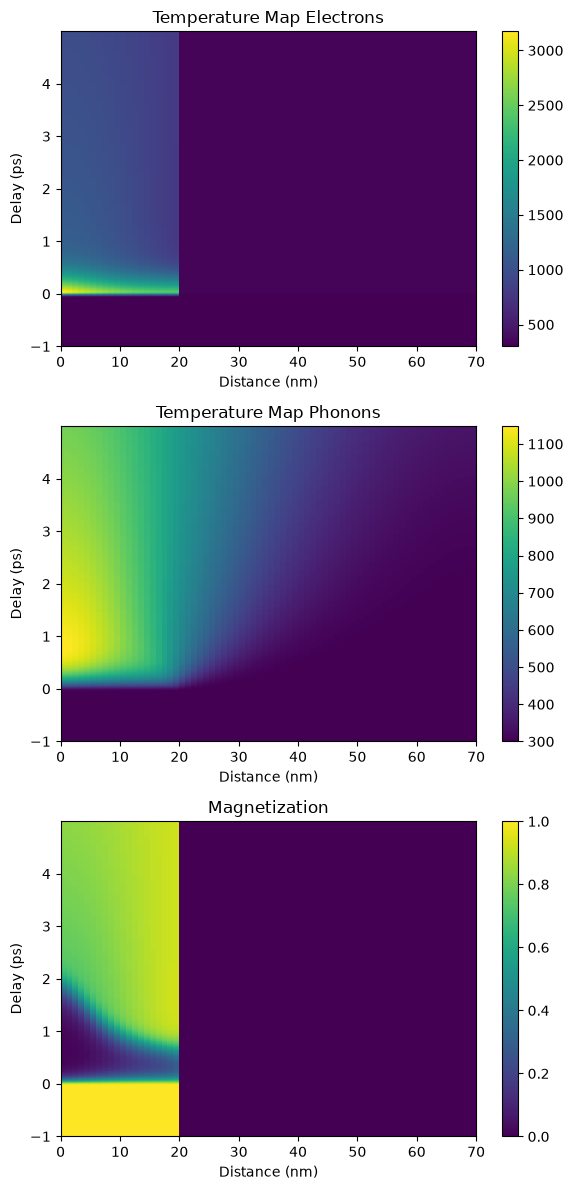

In [21]:
plt.figure(figsize=[6, 12])
plt.subplot(3, 1, 1)
plt.pcolormesh(
    distances.to("nm").magnitude, delays.to("ps").magnitude, temp_map[:, :, 0], shading="auto"
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map Electrons")

plt.subplot(3, 1, 2)
plt.pcolormesh(
    distances.to("nm").magnitude, delays.to("ps").magnitude, temp_map[:, :, 1], shading="auto"
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Temperature Map Phonons")

plt.subplot(3, 1, 3)
plt.pcolormesh(
    distances.to("nm").magnitude, delays.to("ps").magnitude, temp_map[:, :, 2], shading="auto"
)
plt.colorbar()
plt.xlabel("Distance (nm)")
plt.ylabel("Delay (ps)")
plt.title("Magnetization")

plt.tight_layout()
plt.show()

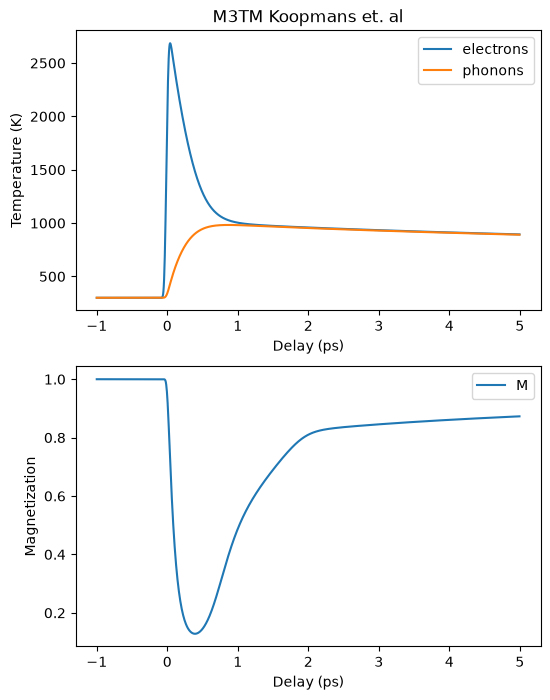

In [22]:
plt.figure(figsize=[6, 8])
plt.subplot(2, 1, 1)
select = S.get_all_positions_per_unique_layer()["CoNi"]
plt.plot(delays.to("ps"), np.mean(temp_map[:, select, 0], 1), label="electrons")
plt.plot(delays.to("ps"), np.mean(temp_map[:, select, 1], 1), label="phonons")
plt.ylabel("Temperature (K)")
plt.xlabel("Delay (ps)")
plt.legend()
plt.title("M3TM Koopmans et. al")

plt.subplot(2, 1, 2)

plt.plot(delays.to("ps"), np.mean(temp_map[:, select, 2], 1), label="M")
plt.ylabel("Magnetization")
plt.xlabel("Delay (ps)")
plt.legend()
plt.show()